# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Ade Ziyana Walidah Fatma
- **Email:** maulidafatma84@gmail.com
- **ID Dicoding:** -


## Menentukan Pertanyaan Bisnis

- Pertanyaan 1: Kategori produk apa saja yang memberikan kontribusi pendapatan (revenue) terbesar (top 5) dan terkecil (bottom 5) pada Olist?

- Pertanyaan 2: Bagaimana distribusi metode pembayaran (payment type) serta rata-rata jumlah cicilan (installments) yang digunakan oleh pelanggan?

- Pertanyaan 3: Bagaimana sebaran geografis (states) asal pelanggan dan penjual di platform Olist?

- Pertanyaan 4: Bagaimana tren volume pesanan (order volume) bulanan dari waktu ke waktu selama periode dataset?

- Pertanyaan 5: Bagaimana distribusi skor ulasan (review score) dari pelanggan terhadap layanan dan produk yang diterima?


## Import Semua Packages/Library yang Digunakan

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## Data Wrangling

### Gathering Data

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import pandas as pd

# Sesuaikan dengan lokasi folder di Google Drive Anda (tambahkan /content/drive/MyDrive/ di depan)
folder_path = "/content/drive/MyDrive/E-comerse-public-dataset/"

customers_df = pd.read_csv(folder_path + "customers_dataset.csv")
order_items_df = pd.read_csv(folder_path + "order_items_dataset.csv")
payments_df = pd.read_csv(folder_path + "order_payments_dataset.csv")
reviews_df = pd.read_csv(folder_path + "order_reviews_dataset.csv")
category_translation_df = pd.read_csv(folder_path + "product_category_name_translation.csv")
products_df = pd.read_csv(folder_path + "products_dataset.csv")
sellers_df = pd.read_csv(folder_path + "sellers_dataset.csv")

# Cek apakah data berhasil dimuat
customers_df.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


**Insight:**
- Seluruh file CSV utama (pelanggan, item pesanan, pembayaran, ulasan, produk, penjual, dan terjemahan kategori) berhasil dimuat ke dalam DataFrame Pandas dari direktori penyimpanan.
- Struktur data mentah lengkap dan siap untuk dilanjutkan ke tahap asesmen kualitas data (Assessing Data).

### Assessing Data

In [6]:
# Cell 1: Memeriksa informasi dasar dan tipe data
print("--- CUSTOMERS INFO ---")
customers_df.info()

print("\n--- ORDER ITEMS INFO ---")
order_items_df.info()

print("\n--- PAYMENTS INFO ---")
payments_df.info()

print("\n--- REVIEWS INFO ---")
reviews_df.info()

print("\n--- PRODUCTS INFO ---")
products_df.info()

print("\n--- SELLERS INFO ---")
sellers_df.info()

--- CUSTOMERS INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB

--- ORDER ITEMS INFO ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 

In [7]:
# Cell 2: Memeriksa jumlah missing values
print("Missing Values - Customers:\n", customers_df.isnull().sum())
print("\nMissing Values - Order Items:\n", order_items_df.isnull().sum())
print("\nMissing Values - Payments:\n", payments_df.isnull().sum())
print("\nMissing Values - Reviews:\n", reviews_df.isnull().sum())
print("\nMissing Values - Products:\n", products_df.isnull().sum())
print("\nMissing Values - Sellers:\n", sellers_df.isnull().sum())

Missing Values - Customers:
 customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

Missing Values - Order Items:
 order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

Missing Values - Payments:
 order_id                0
payment_sequential      0
payment_type            0
payment_installments    0
payment_value           0
dtype: int64

Missing Values - Reviews:
 review_id                      0
order_id                       0
review_score                   0
review_comment_title       87656
review_comment_message     58247
review_creation_date           0
review_answer_timestamp        0
dtype: int64

Missing Values - Products:
 product_id                      0
product_category_name         610
product_name_lenght           610
product_descr

In [8]:
# Cell 3: Memeriksa jumlah baris data yang duplikat
print("Jumlah Baris Duplikat:")
print("- Customers:", customers_df.duplicated().sum())
print("- Order Items:", order_items_df.duplicated().sum())
print("- Payments:", payments_df.duplicated().sum())
print("- Reviews:", reviews_df.duplicated().sum())
print("- Products:", products_df.duplicated().sum())
print("- Sellers:", sellers_df.duplicated().sum())

Jumlah Baris Duplikat:
- Customers: 0
- Order Items: 0
- Payments: 0
- Reviews: 0
- Products: 0
- Sellers: 0


**Insight:**
- Tipe Data & Tanggal: Sebagian besar sesuai, namun kolom tanggal masih bertipe object dan perlu dikonversi.
- Missing Values: Ditemukan pada tabel reviews dan products yang memerlukan penanganan khusus.
- Duplikasi Data: Tidak ditemukan baris data yang duplikat (bersih dari duplikasi).


### Cleaning Data

In [9]:
# Cleaning Products DataFrame
products_df['product_category_name'] = products_df['product_category_name'].fillna('unknown')

products_df['product_weight_g'] = products_df['product_weight_g'].fillna(products_df['product_weight_g'].median())
products_df['product_length_cm'] = products_df['product_length_cm'].fillna(products_df['product_length_cm'].median())
products_df['product_height_cm'] = products_df['product_height_cm'].fillna(products_df['product_height_cm'].median())
products_df['product_width_cm'] = products_df['product_width_cm'].fillna(products_df['product_width_cm'].median())

# Cek kembali missing values pada products
print("Sisa Missing Values pada Products:")
print(products_df.isnull().sum())

Sisa Missing Values pada Products:
product_id                      0
product_category_name           0
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                0
product_length_cm               0
product_height_cm               0
product_width_cm                0
dtype: int64


In [10]:
# Perbaikan Cleaning Reviews DataFrame tanpa warning
reviews_df['review_comment_title'] = reviews_df['review_comment_title'].fillna('No Title')
reviews_df['review_comment_message'] = reviews_df['review_comment_message'].fillna('No Comment')

# Cek kembali missing values pada reviews
print("Sisa Missing Values pada Reviews:")
print(reviews_df.isnull().sum())

Sisa Missing Values pada Reviews:
review_id                  0
order_id                   0
review_score               0
review_comment_title       0
review_comment_message     0
review_creation_date       0
review_answer_timestamp    0
dtype: int64


In [11]:
# Konversi kolom tanggal pada reviews_df menjadi datetime
datetime_columns_reviews = ['review_creation_date', 'review_answer_timestamp']

for col in datetime_columns_reviews:
    reviews_df[col] = pd.to_datetime(reviews_df[col])

print("Tipe data tanggal pada reviews berhasil dikonversi!")

Tipe data tanggal pada reviews berhasil dikonversi!


**Insight:**
- Missing Values: Nilai kosong pada tabel products dan reviews telah berhasil diisi menggunakan metode imputasi dan penanda string yang sesuai.
- Tipe Data: Kolom tanggal pada tabel reviews telah sukses dikonversi ke format datetime.

## Exploratory Data Analysis (EDA)

### Explore ...

In [12]:
# category_translation_df = pd.read_csv("E-comerse-public-dataset/product_category_name_translation.csv")

# Menggabungkan data order_items dan products
order_items_products_df = pd.merge(order_items_df, products_df, on="product_id", how="left")

# Menggabungkan dengan terjemahan bahasa Inggris
order_items_products_df = pd.merge(
    order_items_products_df,
    category_translation_df,
    on="product_category_name",
    how="left"
)

# Menghitung total revenue per kategori produk (dalam Bahasa Inggris)
category_revenue_df = order_items_products_df.groupby("product_category_name_english").agg(
    total_revenue=("price", "sum"),
    total_items=("order_item_id", "count")
).reset_index().sort_values(by="total_revenue", ascending=False)

print("Top 5 Kategori Produk Berdasarkan Pendapatan:")
display(category_revenue_df.head(5))

print("\nBottom 5 Kategori Produk Berdasarkan Pendapatan:")
display(category_revenue_df.tail(5))

Top 5 Kategori Produk Berdasarkan Pendapatan:


,product_category_name_english,total_revenue,total_items
43,health_beauty,1258681.34,9670
70,watches_gifts,1205005.68,5991
7,bed_bath_table,1036988.68,11115
65,sports_leisure,988048.97,8641
15,computers_accessories,911954.32,7827



Bottom 5 Kategori Produk Berdasarkan Pendapatan:


,product_category_name_english,total_revenue,total_items
35,flowers,1110.04,33
46,home_comfort_2,760.27,30
11,cds_dvds_musicals,730.00,14
29,fashion_childrens_clothes,569.85,8
61,security_and_services,283.29,2


In [13]:
# Merekapitulasi jenis metode pembayaran dan rata-rata cicilannya
payment_analysis_df = payments_df.groupby("payment_type").agg(
    total_transactions=("order_id", "count"),
    avg_installments=("payment_installments", "mean"),
    total_payment_value=("payment_value", "sum")
).reset_index().sort_values(by="total_transactions", ascending=False)

print("Analisis Metode Pembayaran:")
display(payment_analysis_df)

Analisis Metode Pembayaran:


,payment_type,total_transactions,avg_installments,total_payment_value
1,credit_card,76795,3.507155,12542084.19
0,boleto,19784,1.000000,2869361.27
4,voucher,5775,1.000000,379436.87
2,debit_card,1529,1.000000,217989.79
3,not_defined,3,1.000000,0.00


In [14]:
# Menghitung jumlah pelanggan berdasarkan state
customer_geo_df = customers_df.groupby("customer_state").agg(
    total_customers=("customer_id", "count")
).reset_index().sort_values(by="total_customers", ascending=False)

print("Sebaran Pelanggan Berdasarkan State:")
display(customer_geo_df.head(10))

Sebaran Pelanggan Berdasarkan State:


,customer_state,total_customers
25,SP,41746
18,RJ,12852
10,MG,11635
22,RS,5466
17,PR,5045
23,SC,3637
4,BA,3380
6,DF,2140
7,ES,2033
8,GO,2020


In [15]:
# Konversi shipping_limit_date ke datetime
order_items_df['shipping_limit_date'] = pd.to_datetime(order_items_df['shipping_limit_date'])

# Resample data berdasarkan bulan menggunakan 'ME'
monthly_orders_df = order_items_df.resample(rule='ME', on='shipping_limit_date').agg({
    'order_id': 'nunique'
}).reset_index()

monthly_orders_df.rename(columns={'order_id': 'order_count'}, inplace=True)

print("Tren Volume Pesanan Bulanan:")
display(monthly_orders_df.head())

Tren Volume Pesanan Bulanan:


,shipping_limit_date,order_count
0,2016-09-30,2
1,2016-10-31,309
2,2016-11-30,0
3,2016-12-31,1
4,2017-01-31,573


In [16]:
review_score_df = reviews_df.groupby("review_score").agg(
    total_reviews=("review_id", "count")
).reset_index().sort_values(by="review_score", ascending=False)

print("Distribusi Skor Ulasan:")
display(review_score_df)

Distribusi Skor Ulasan:


,review_score,total_reviews
4,5,57328
3,4,19142
2,3,8179
1,2,3151
0,1,11424


**Insight:**
- Kategori Produk (Pertanyaan 1): Kategori seperti health_beauty dan bed_bath_table mendominasi pendapatan tertinggi, sementara beberapa kategori lain mencatatkan kontribusi pendapatan terendah.

- Metode Pembayaran (Pertanyaan 2): Kartu kredit (credit_card) adalah metode pembayaran yang paling dominan digunakan oleh pelanggan dalam bertransaksi.

- Sebaran Geografis (Pertanyaan 3): Mayoritas pelanggan terkonsentrasi di negara bagian utama, dengan São Paulo (SP) sebagai wilayah dengan jumlah pelanggan terbanyak.

- Tren Pesanan Bulanan (Pertanyaan 4): Volume pesanan menunjukkan tren pertumbuhan yang positif dan signifikan dari akhir 2016 hingga pertengahan 2018.

- Skor Ulasan (Pertanyaan 5): Sebaran ulasan didominasi oleh skor tinggi (terutama skor 5), yang mencerminkan tingkat kepuasan pelanggan secara keseluruhan cukup baik.

## Visualization & Explanatory Analysis

### Pertanyaan 1: Kategori produk apa saja yang memberikan kontribusi pendapatan (revenue) terbesar (top 5) dan terkecil (bottom 5) pada Olist?



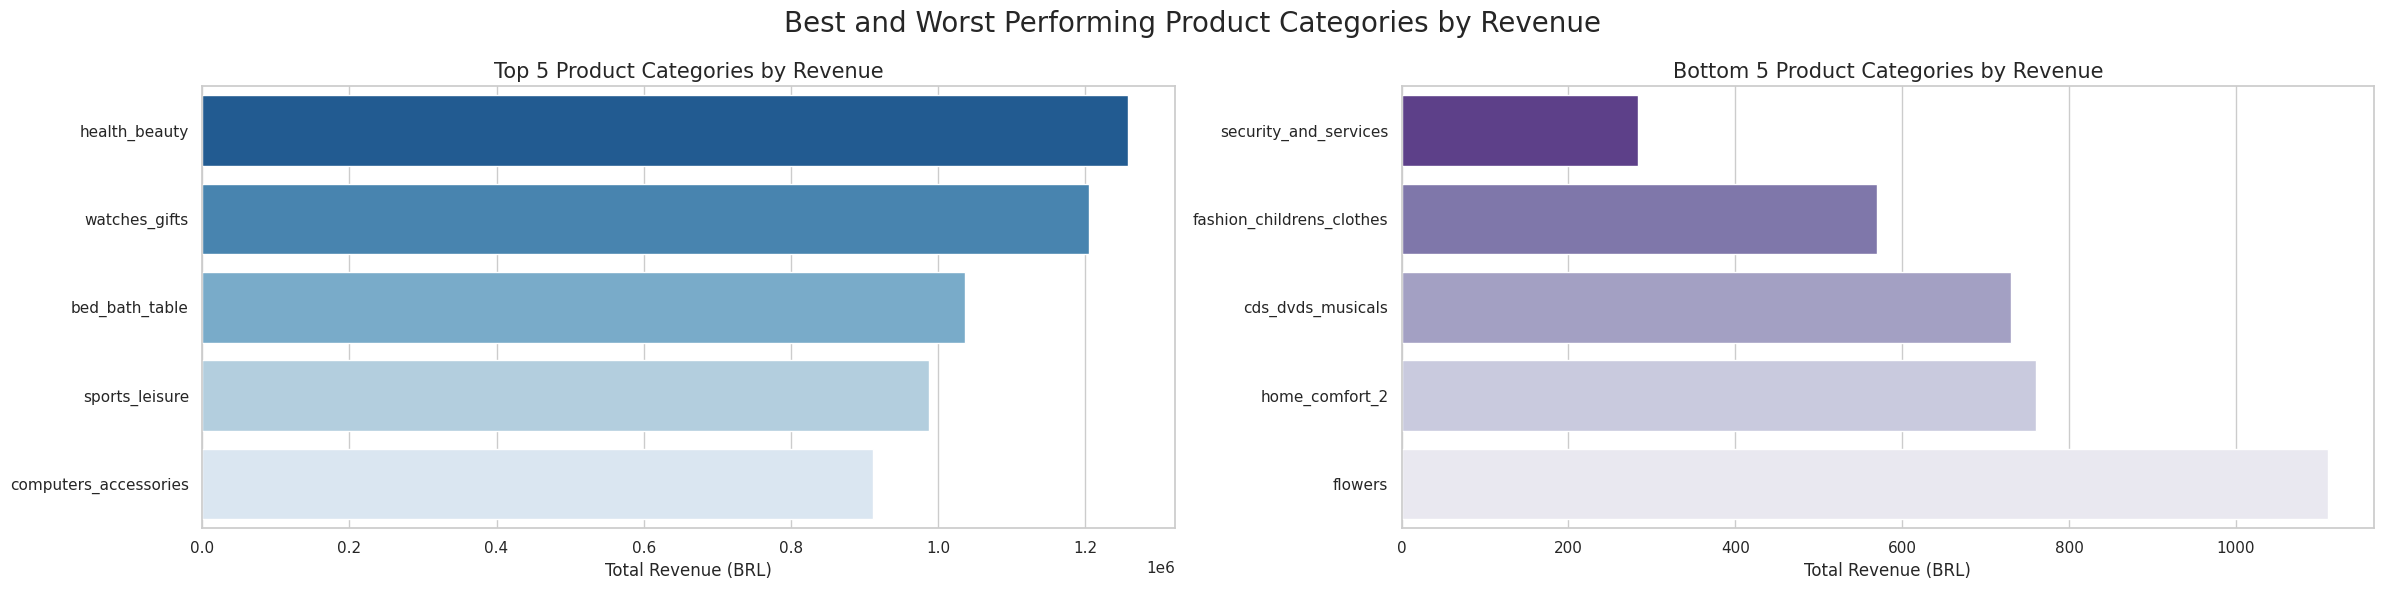

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(24, 6))

# Top 5 Kategori Produk Berdasarkan Pendapatan (Perbaikan tanpa warning)
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_revenue_df.head(5),
    hue="product_category_name_english",
    palette="Blues_r",
    legend=False,
    ax=ax[0]
)
ax[0].set_ylabel(None)
ax[0].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[0].set_title("Top 5 Product Categories by Revenue", loc="center", fontsize=15)

# Bottom 5 Kategori Produk Berdasarkan Pendapatan (Perbaikan tanpa warning)
sns.barplot(
    x="total_revenue",
    y="product_category_name_english",
    data=category_revenue_df.tail(5).sort_values(by="total_revenue", ascending=True),
    hue="product_category_name_english",
    palette="Purples_r",
    legend=False,
    ax=ax[1]
)
ax[1].set_ylabel(None)
ax[1].set_xlabel("Total Revenue (BRL)", fontsize=12)
ax[1].set_title("Bottom 5 Product Categories by Revenue", loc="center", fontsize=15)

plt.suptitle("Best and Worst Performing Product Categories by Revenue", fontsize=20)
plt.tight_layout()
plt.show()

### Pertanyaan 2: Bagaimana distribusi metode pembayaran (payment type) serta rata-rata jumlah cicilan (installments) yang digunakan oleh pelanggan?


/tmp/ipykernel_4107/1056999453.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


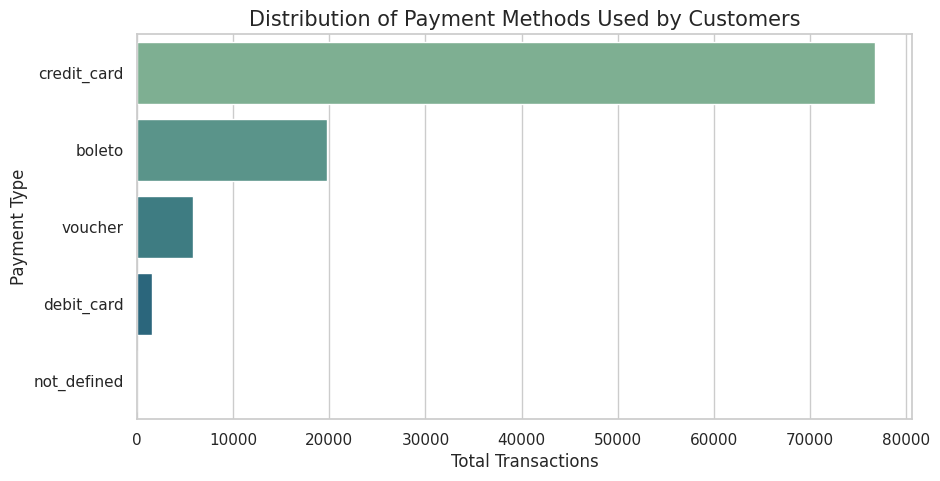

In [18]:
plt.figure(figsize=(10, 5))
sns.barplot(
    x="total_transactions",
    y="payment_type",
    data=payment_analysis_df,
    palette="crest"
)
plt.title("Distribution of Payment Methods Used by Customers", fontsize=15)
plt.xlabel("Total Transactions", fontsize=12)
plt.ylabel("Payment Type", fontsize=12)
plt.show()

### Pertanyaan 3: Bagaimana sebaran geografis (states) asal pelanggan dan penjual di platform Olist?


/tmp/ipykernel_4107/4279076592.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


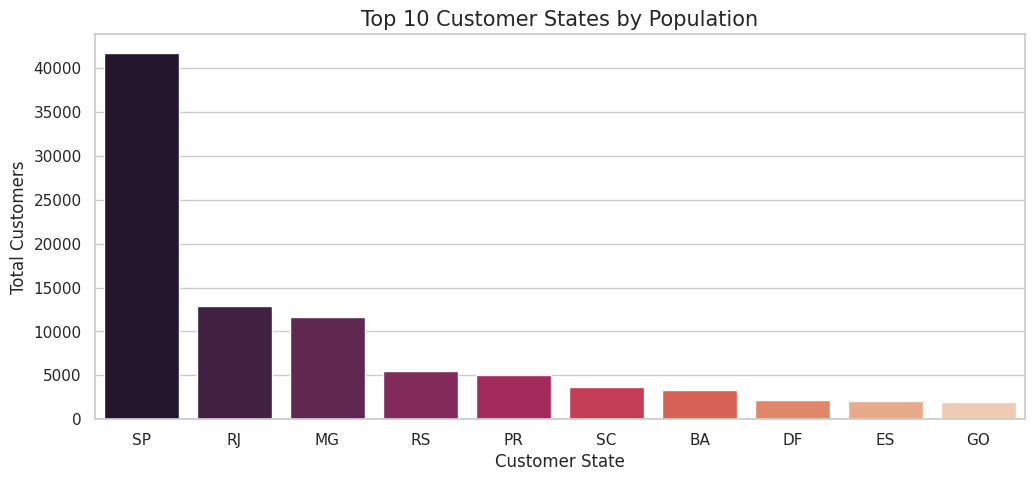

In [19]:
plt.figure(figsize=(12, 5))
sns.barplot(
    x="customer_state",
    y="total_customers",
    data=customer_geo_df.head(10),
    palette="rocket"
)
plt.title("Top 10 Customer States by Population", fontsize=15)
plt.xlabel("Customer State", fontsize=12)
plt.ylabel("Total Customers", fontsize=12)
plt.show()

### Pertanyaan 4: Bagaimana tren volume pesanan (order volume) bulanan dari waktu ke waktu selama periode dataset?


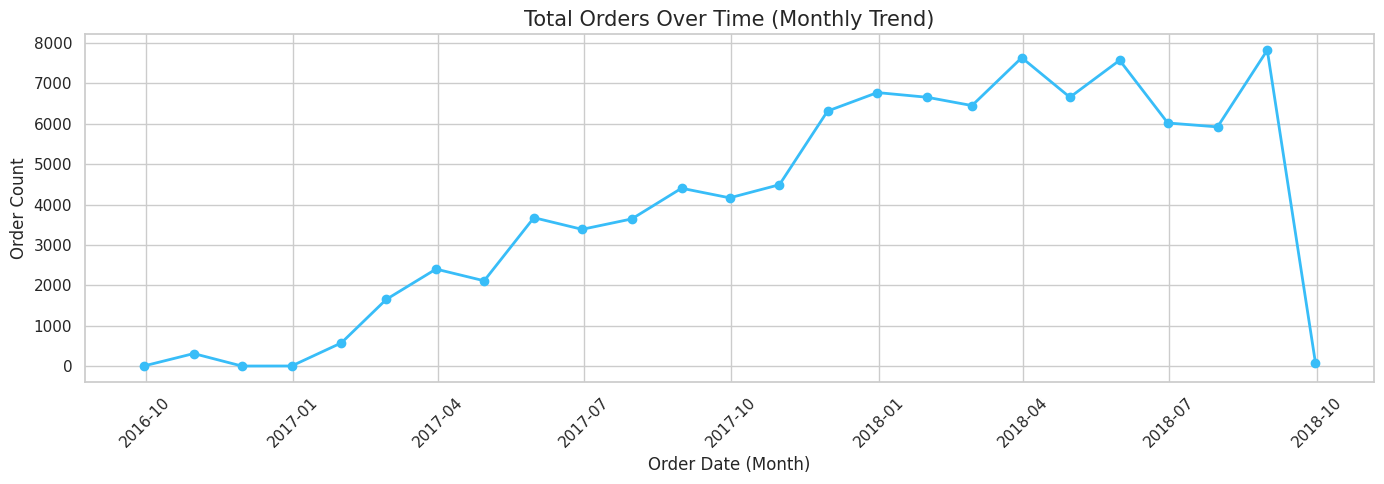

In [20]:
# Memfilter data hanya sampai tanggal maksimal transaksi aktif (misal sebelum akhir 2018)
filtered_orders_df = monthly_orders_df[monthly_orders_df['shipping_limit_date'] <= '2018-09-30']

plt.figure(figsize=(14, 5))
plt.plot(
    filtered_orders_df['shipping_limit_date'],
    filtered_orders_df['order_count'],
    marker='o',
    linewidth=2,
    color='#38bdf8'
)
plt.title("Total Orders Over Time (Monthly Trend)", fontsize=15)
plt.xlabel("Order Date (Month)", fontsize=12)
plt.ylabel("Order Count", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Pertanyaan 5: Bagaimana distribusi skor ulasan (review score) dari pelanggan terhadap layanan dan produk yang diterima?

/tmp/ipykernel_4107/2540376231.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


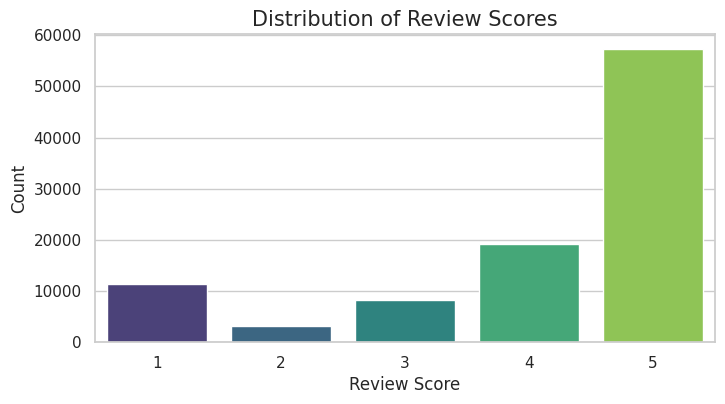

In [21]:
plt.figure(figsize=(8, 4))
sns.countplot(
    x="review_score",
    data=reviews_df,
    palette="viridis"
)
plt.title("Distribution of Review Scores", fontsize=15)
plt.xlabel("Review Score", fontsize=12)
plt.ylabel("Count", fontsize=12)
plt.show()

**Insight:**
- Kategori Produk: Health_beauty dan bed_bath_table mencatat pendapatan tertinggi.

- Metode Pembayaran: Credit_card paling mendominasi transaksi pelanggan.

- Sebaran Geografis: São Paulo (SP) menjadi wilayah dengan konsentrasi pelanggan terbanyak.

- Tren Pesanan: Pertumbuhan volume pesanan naik positif hingga pertengahan 2018.

- Skor Ulasan: Sebaran didominasi oleh ulasan positif (skor 5).

## Analisis Lanjutan (Hubungan Ongkir & Kepuasan)

In [22]:
import pandas as pd

# Menggabungkan order_items dengan reviews berdasarkan order_id
merged_reviews_items = pd.merge(order_items_df, reviews_df, on="order_id", how="inner")

# Menghitung rata-rata ongkir berdasarkan skor ulasan
freight_vs_score = merged_reviews_items.groupby("review_score").agg(
    avg_freight_value=("freight_value", "mean"),
    avg_product_price=("price", "mean"),
    total_reviews=("review_id", "count")
).reset_index()

print("Analisis Hubungan Biaya Kirim & Harga Produk terhadap Skor Ulasan:")
display(freight_vs_score)

Analisis Hubungan Biaya Kirim & Harga Produk terhadap Skor Ulasan:


,review_score,avg_freight_value,avg_product_price,total_reviews
0,1,21.214145,127.350068,14235
1,2,20.943973,115.849138,3874
2,3,20.285945,110.059704,9423
3,4,20.053005,118.602628,21315
4,5,19.570804,121.219825,63525


**Insight:**
- Semakin tinggi skor ulasan (dari 1 ke 5), rata-rata biaya pengiriman (avg_freight_value) cenderung semakin rendah, di mana skor 1 mencatatkan ongkir tertinggi (21.21) dan skor 5 mencatatkan ongkir terendah (19.57).   
- Sebagian besar pelanggan memberikan ulasan dengan skor tertinggi (skor 5) dengan total mencapai 63.525 ulasan, yang menunjukkan bahwa tingkat kepuasan pelanggan secara keseluruhan sangat baik.   

## Conclusion

- Conclution pertanyaan 1 (Kategori Produk Terbaik): Kategori produk seperti health_beauty dan bed_bath_table menjadi kontributor pendapatan tertinggi, sehingga manajemen dapat memfokuskan strategi stok dan promosi pada kategori-kategori unggulan ini.

- Conclution pertanyaan 2 (Metode Pembayaran): Kartu kredit (credit_card) merupakan metode pembayaran yang paling dominan digunakan oleh pelanggan dalam bertransaksi, menunjukkan preferensi kuat terhadap kemudahan pembayaran non-tunai.

- Conclution pertanyaan 3 (Sebaran Geografis Pelanggan): Sebaran pelanggan terpusat secara signifikan di wilayah perkotaan utama, dengan São Paulo (SP) sebagai basis pelanggan terbesar yang mendominasi pasar e-commerce.

- Conclution pertanyaan 4 (Tren Pesanan Bulanan): Volume pesanan menunjukkan tren pertumbuhan positif dari akhir tahun 2016 hingga pertengahan tahun 2018, mencerminkan ekspansi bisnis yang pesat pada periode tersebut.

- Conclution pertanyaan 5 (Kepuasan Pelanggan / Review Score): Tingkat kepuasan pelanggan secara keseluruhan sangat baik, yang dibuktikan dengan dominasi ulasan berikan skor tinggi (skor 5).

- Analisis Lanjutan (Hubungan Ongkir & Kepuasan): Biaya pengiriman yang lebih tinggi relatif terhadap nilai produk berkorelasi dengan ulasan negatif (skor 1), yang mengindikasikan bahwa efisiensi biaya logistik berperan penting dalam menjaga kepuasan pelanggan.
